<div align="center">

# Assignment 8 — Principal Component Analysis (PCA)

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 8 — Principal Component Analysis (PCA)

*Unsupervised Learning: Dimensionality Reduction, Covariance Eigen-Decomposition, and Feature Projection*

**Datasets:** Wine (13 chemical features, 3 cultivars) and Digits ($8 \times 8$ handwritten digits = 64 pixel features) — built into scikit-learn.

**Objective:** Implement PCA from scratch through eigen-decomposition of the covariance matrix, verify it against scikit-learn, and use PCA for visualisation, compression and as a preprocessing step for classification.

## 1. Theory

PCA finds a new set of orthogonal axes — the **principal components** — ordered by how much of the data's variance they capture. Keeping only the first few components reduces the number of features while losing as little information as possible.

**Step 1 — Standardise** every feature, since PCA is driven by variance and would otherwise be dominated by large-scale features:

$$z = \frac{x - \mu}{\sigma}$$

**Step 2 — Covariance matrix** of the standardised data $Z$ ($n$ samples $\times$ $d$ features):

$$\Sigma = \frac{1}{n-1} Z^\top Z$$

**Step 3 — Eigen-decomposition.** $\Sigma$ is symmetric, so it has real eigenvalues and orthogonal eigenvectors:

$$\Sigma \, \mathbf{w}_i = \lambda_i \, \mathbf{w}_i, \qquad \lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d$$

Eigenvector $\mathbf{w}_i$ is the direction of component $i$ (its entries are the **loadings** of each original feature) and eigenvalue $\lambda_i$ is the variance along it. The **explained variance ratio** is $\lambda_i / \sum_j \lambda_j$.

**Step 4 — Projection** onto the top $k$ eigenvectors $W_k = [\mathbf{w}_1, \dots, \mathbf{w}_k]$, and reconstruction back to the original space:

$$Y = Z W_k \qquad\qquad \hat{Z} = Y W_k^\top$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — PCA from Scratch (Wine)

Wine dataset: 178 wines from 3 cultivars, 13 chemical measurements (alcohol, flavanoids, colour intensity, proline, ...).

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['cultivar'] = pd.Categorical.from_codes(wine.target, wine.target_names)
print('Shape:', df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [3]:
df.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Feature scales differ by orders of magnitude (`proline` has a std of ~315, `hue` ~0.2). Without standardisation, `proline` alone would dominate the first component.

## Steps 1–2: Standardise and Build the Covariance Matrix

In [4]:
X = wine.data
y = wine.target

# Step 1 — standardise (population std, same as StandardScaler)
Z = (X - X.mean(axis=0)) / X.std(axis=0)

# Step 2 — covariance matrix
n = Z.shape[0]
cov = (Z.T @ Z) / (n - 1)

print('Covariance matrix shape:', cov.shape)
print('Matches np.cov         :', np.allclose(cov, np.cov(Z, rowvar=False)))

Covariance matrix shape: (13, 13)
Matches np.cov         : True


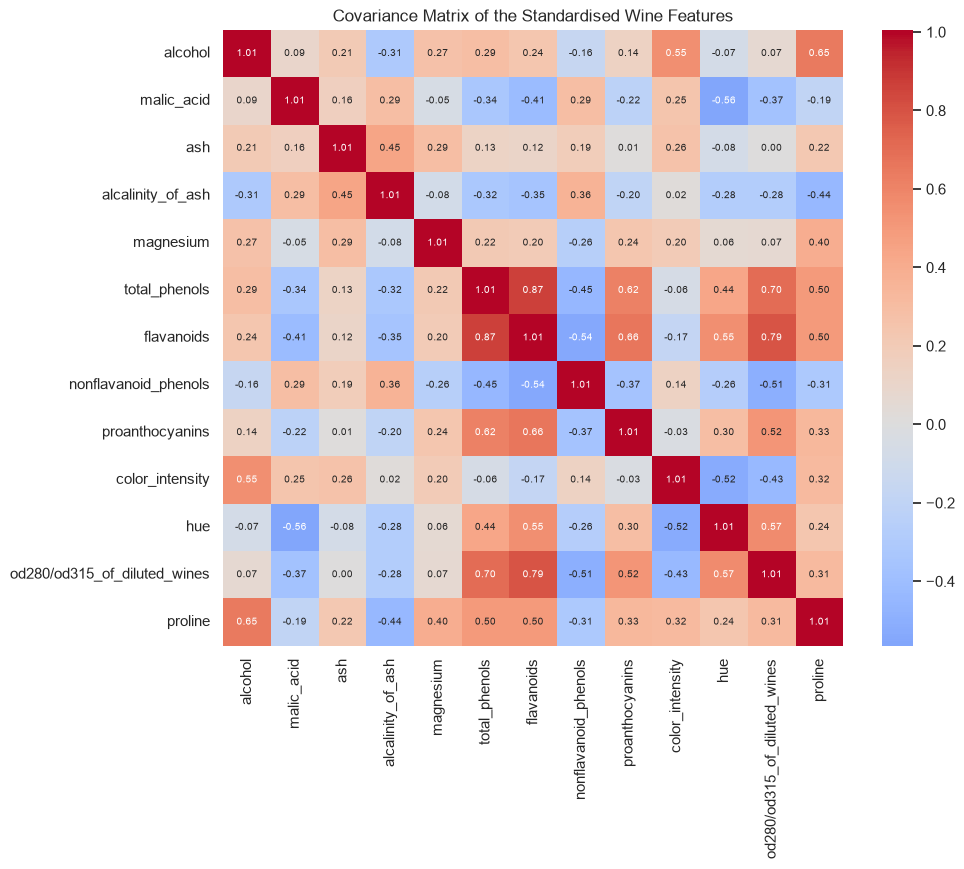

In [5]:
cov_df = pd.DataFrame(cov, index=wine.feature_names,
                      columns=wine.feature_names)
plt.figure(figsize=(10, 8))
sns.heatmap(cov_df, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7})
plt.title('Covariance Matrix of the Standardised Wine Features')
plt.show()

Strong off-diagonal blocks (e.g. `flavanoids`, `total_phenols` and `od280/od315`) mean several features carry overlapping information — exactly the redundancy PCA compresses away.

## Step 3: Eigen-Decomposition

In [6]:
# eigh is for symmetric matrices; it returns eigenvalues in ascending order
eig_vals, eig_vecs = np.linalg.eigh(cov)
order = np.argsort(eig_vals)[::-1]
eig_vals, eig_vecs = eig_vals[order], eig_vecs[:, order]

explained = eig_vals / eig_vals.sum()
eig_table = pd.DataFrame({'Eigenvalue': eig_vals,
                          'Explained variance': explained,
                          'Cumulative': np.cumsum(explained)},
                         index=[f'PC{i + 1}' for i in range(len(eig_vals))])
eig_table.round(3)

,Eigenvalue,Explained variance,Cumulative
PC1,4.732,0.362,0.362
PC2,2.511,0.192,0.554
PC3,1.454,0.111,0.665
PC4,0.924,0.071,0.736
PC5,0.858,0.066,0.802
PC6,0.645,0.049,0.851
PC7,0.554,0.042,0.893
PC8,0.350,0.027,0.920
PC9,0.291,0.022,0.942
PC10,0.252,0.019,0.962


In [7]:
d = cov.shape[0]
W, L = eig_vecs, np.diag(eig_vals)
print('Eigenvectors orthonormal (W^T W = I) :', np.allclose(W.T @ W, np.eye(d)))
print('Covariance rebuilt (W L W^T = Sigma) :', np.allclose(W @ L @ W.T, cov))
print('Sum of eigenvalues = total variance  :',
      np.isclose(eig_vals.sum(), np.trace(cov)))

Eigenvectors orthonormal (W^T W = I) : True
Covariance rebuilt (W L W^T = Sigma) : True
Sum of eigenvalues = total variance  : True


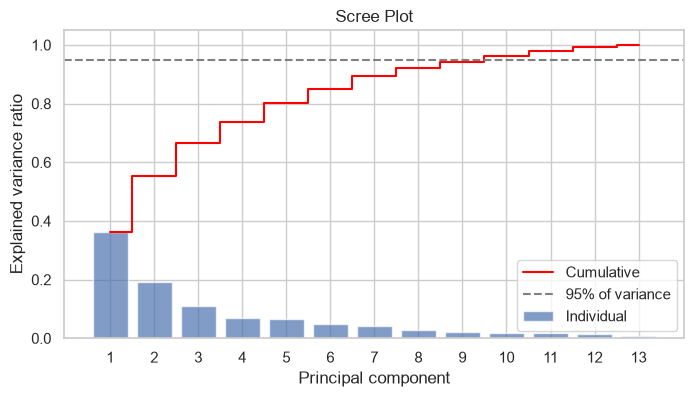

PC1 + PC2 explain 55.4% of the total variance
Components needed for 95% of the variance: 10 of 13


In [8]:
pcs = np.arange(1, d + 1)
k95 = int(np.argmax(np.cumsum(explained) >= 0.95)) + 1

plt.figure(figsize=(8, 4))
plt.bar(pcs, explained, alpha=0.7, label='Individual')
plt.step(pcs, np.cumsum(explained), where='mid', color='red',
         label='Cumulative')
plt.axhline(0.95, ls='--', color='gray', label='95% of variance')
plt.xticks(pcs)
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.title('Scree Plot')
plt.legend()
plt.show()

print(f'PC1 + PC2 explain {explained[:2].sum():.1%} of the total variance')
print(f'Components needed for 95% of the variance: {k95} of {d}')

## Step 4: Projection onto the Principal Components

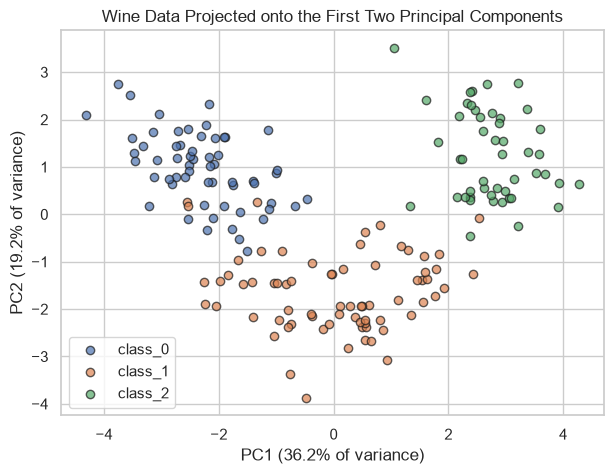

In [9]:
W2 = eig_vecs[:, :2]
Y = Z @ W2

plt.figure(figsize=(7, 5))
for cls, name in enumerate(wine.target_names):
    plt.scatter(Y[y == cls, 0], Y[y == cls, 1], label=name,
                alpha=0.7, edgecolor='k')
plt.xlabel(f'PC1 ({explained[0]:.1%} of variance)')
plt.ylabel(f'PC2 ({explained[1]:.1%} of variance)')
plt.title('Wine Data Projected onto the First Two Principal Components')
plt.legend()
plt.show()

PCA never saw the labels, yet the three cultivars separate almost cleanly in 2D — 13 dimensions squeezed into 2 while keeping most of the structure.

## Loadings — What Do the Components Mean?

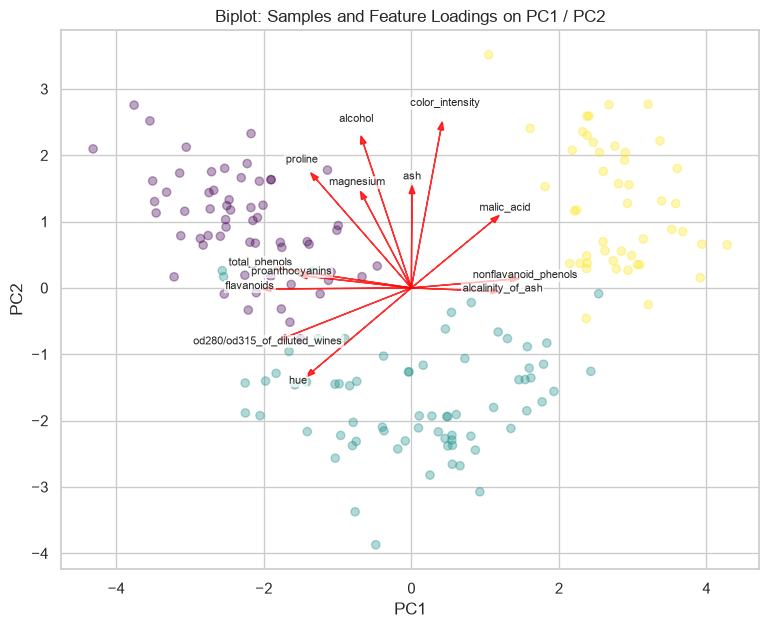

In [10]:
plt.figure(figsize=(9, 7))
plt.scatter(Y[:, 0], Y[:, 1], c=y, cmap='viridis', alpha=0.35)
arrows = W2 * 4.5
for (dx, dy), feat in zip(arrows, wine.feature_names):
    plt.arrow(0, 0, dx, dy, color='red', alpha=0.8, head_width=0.08)
    plt.text(dx * 1.15, dy * 1.15, feat, fontsize=8, ha='center',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Biplot: Samples and Feature Loadings on PC1 / PC2')
plt.show()

In [11]:
loadings = pd.DataFrame(eig_vecs[:, :2], index=wine.feature_names,
                        columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    parts = [f'{f} ({loadings.loc[f, pc]:+.2f})' for f in top]
    print(f'{pc} driven by:', ', '.join(parts))

PC1 driven by: flavanoids (-0.42), total_phenols (-0.39), od280/od315_of_diluted_wines (-0.38), proanthocyanins (-0.31)
PC2 driven by: color_intensity (+0.53), alcohol (+0.48), proline (+0.36), ash (+0.32)


## Verification against scikit-learn

In [12]:
Z_sk = StandardScaler().fit_transform(X)
pca = PCA().fit(Z_sk)
Y_sk = pca.transform(Z_sk)[:, :2]

print('Eigenvalues match sklearn      :',
      np.allclose(eig_vals, pca.explained_variance_))
print('Variance ratios match sklearn  :',
      np.allclose(explained, pca.explained_variance_ratio_))
# eigenvectors are only unique up to sign, so compare absolute values
print('Components match (up to sign)  :',
      np.allclose(np.abs(eig_vecs.T), np.abs(pca.components_)))
print('Projections match (up to sign) :', np.allclose(np.abs(Y), np.abs(Y_sk)))

Eigenvalues match sklearn      : True
Variance ratios match sklearn  : True
Components match (up to sign)  : True
Projections match (up to sign) : True


---
# Part B — PCA for Compression & Classification (Digits)

Digits dataset: 1,797 grey-scale images of handwritten digits, each $8 \times 8$ pixels (intensity 0–16) flattened to 64 features. All pixels share the same unit, so here PCA only centres the data — no standardisation.

Shape: (1797, 64)


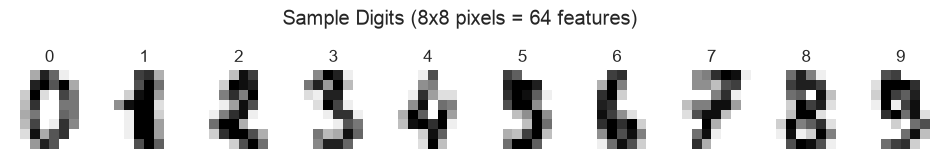

In [13]:
digits = load_digits()
Xd, yd = digits.data, digits.target
print('Shape:', Xd.shape)

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for ax, img, label in zip(axes, digits.images, yd):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')
plt.suptitle('Sample Digits (8x8 pixels = 64 features)', y=1.05)
plt.show()

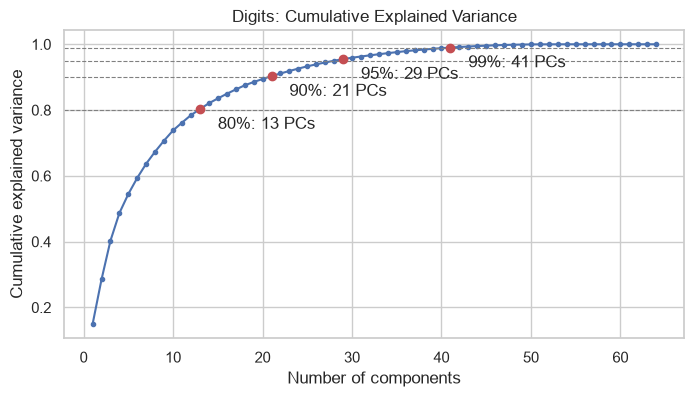

In [14]:
pca_d = PCA().fit(Xd)
cum = np.cumsum(pca_d.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 65), cum, 'o-', markersize=3)
for t in [0.80, 0.90, 0.95, 0.99]:
    k = int(np.argmax(cum >= t)) + 1
    plt.axhline(t, ls='--', color='gray', lw=0.8)
    plt.plot(k, cum[k - 1], 'ro')
    plt.annotate(f'{t:.0%}: {k} PCs', (k, cum[k - 1]),
                 xytext=(k + 2, cum[k - 1] - 0.06))
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Digits: Cumulative Explained Variance')
plt.show()

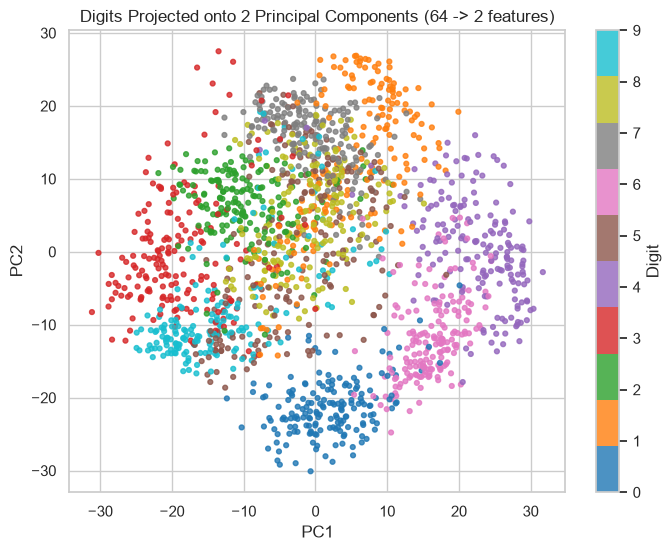

Variance kept by 2 components: 28.5%


In [15]:
Yd = PCA(n_components=2).fit_transform(Xd)

plt.figure(figsize=(8, 6))
sc = plt.scatter(Yd[:, 0], Yd[:, 1], c=yd, cmap='tab10', s=12, alpha=0.8)
plt.colorbar(sc, ticks=range(10), label='Digit')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Digits Projected onto 2 Principal Components (64 -> 2 features)')
plt.show()

print(f'Variance kept by 2 components: {cum[1]:.1%}')

Even in 2D, digits such as 0, 4 and 6 form their own regions; the rest overlap because 2 components keep less than 30% of the variance.

## Compression: Reconstructing Images from $k$ Components

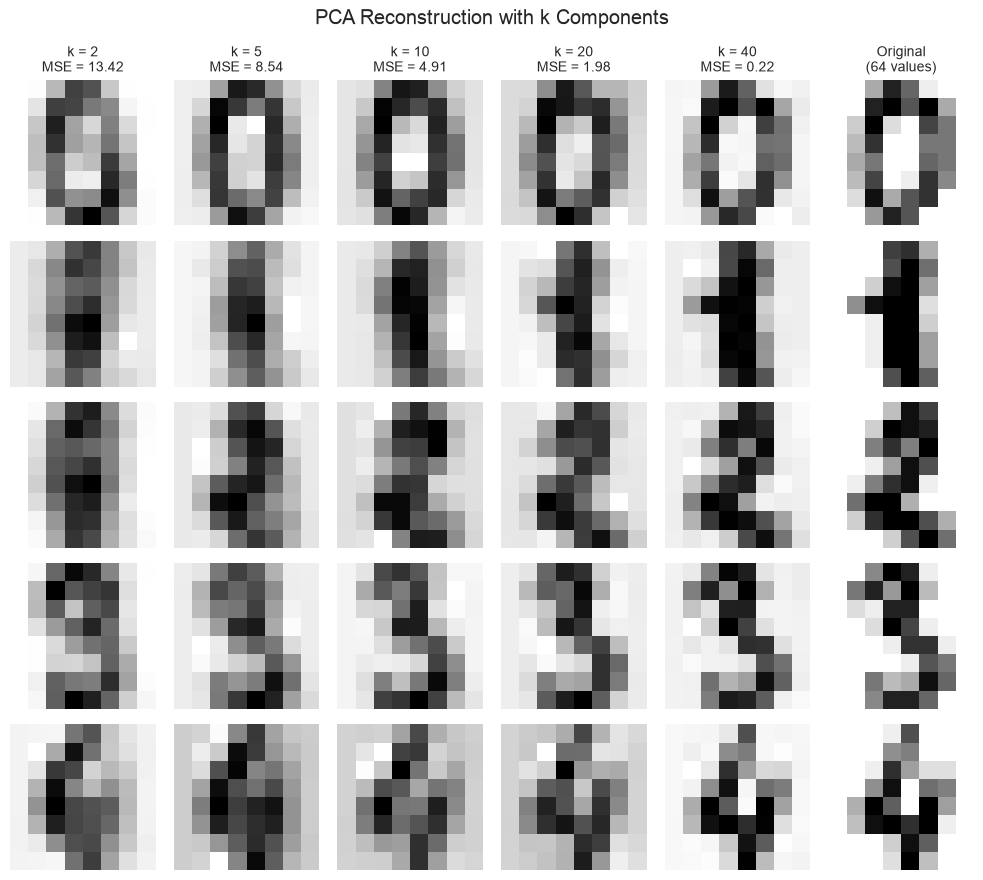

In [16]:
ks = [2, 5, 10, 20, 40]
samples = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(len(samples), len(ks) + 1, figsize=(10, 9))
for col, k in enumerate(ks):
    p = PCA(n_components=k).fit(Xd)
    recon = p.inverse_transform(p.transform(Xd))
    mse = np.mean((Xd - recon) ** 2)
    for row, s in enumerate(samples):
        axes[row, col].imshow(recon[s].reshape(8, 8), cmap='gray_r')
        axes[row, col].axis('off')
    axes[0, col].set_title(f'k = {k}\nMSE = {mse:.2f}', fontsize=10)
for row, s in enumerate(samples):
    axes[row, -1].imshow(digits.images[s], cmap='gray_r')
    axes[row, -1].axis('off')
axes[0, -1].set_title('Original\n(64 values)', fontsize=10)
plt.suptitle('PCA Reconstruction with k Components')
plt.tight_layout()
plt.show()

With ~20 of 64 numbers per image the digits are already easy to read — a 3x compression.

## PCA as Preprocessing for Classification

In [17]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.25, random_state=42, stratify=yd)

n_comp = [2, 5, 10, 15, 20, 30, 40, 64]
rows = []
for k in n_comp:
    model = make_pipeline(PCA(n_components=k),
                          LogisticRegression(max_iter=5000))
    model.fit(Xd_train, yd_train)
    kept = model.named_steps['pca'].explained_variance_ratio_.sum()
    rows.append({'Components': k,
                 'Variance kept': kept,
                 'Test accuracy': model.score(Xd_test, yd_test)})
res = pd.DataFrame(rows)
res.round(3)

,Components,Variance kept,Test accuracy
0,2,0.284,0.591
1,5,0.547,0.838
2,10,0.738,0.916
3,15,0.835,0.936
4,20,0.895,0.929
5,30,0.959,0.958
6,40,0.988,0.958
7,64,1.000,0.962


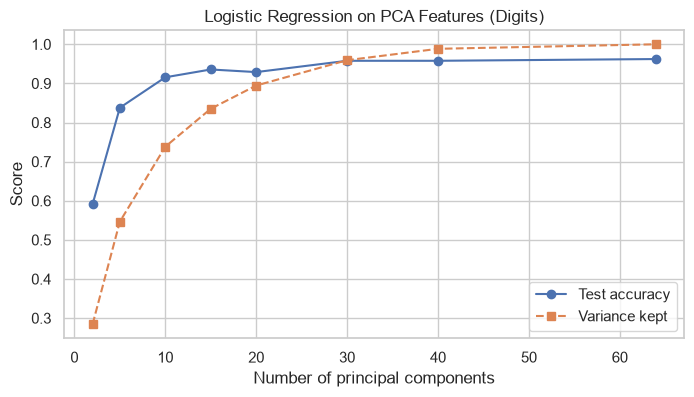

In [18]:
plt.figure(figsize=(8, 4))
plt.plot(res['Components'], res['Test accuracy'], 'o-', label='Test accuracy')
plt.plot(res['Components'], res['Variance kept'], 's--', label='Variance kept')
plt.xlabel('Number of principal components')
plt.ylabel('Score')
plt.title('Logistic Regression on PCA Features (Digits)')
plt.legend()
plt.show()

## Conclusion

- **From scratch = scikit-learn:** standardising, building $\Sigma = \frac{1}{n-1}Z^\top Z$ and running `eigh` gives exactly the same eigenvalues, variance ratios and projections as `sklearn.decomposition.PCA` (eigenvectors match up to sign).
- **Wine:** PC1 + PC2 keep **~55%** of the variance, yet the 3 cultivars separate almost perfectly in 2D; **10 of 13** components are needed for 95%. PC1 is a "phenols/flavanoids" axis, PC2 an "alcohol/colour intensity/proline" axis.
- **Digits:** 95% of the pixel variance fits in **29 of 64** components; images stay recognisable at ~20 components.
- **Classification:** logistic regression on **30 components** scores **95.8%** vs **96.2%** with all 64 pixels — less than half the features for almost no loss. Too few components hurts (2 PCs: ~59%).
- Caveats: PCA is linear and unsupervised (it maximises variance, not class separation), components are harder to interpret than raw features, and features must be **scaled** when their units differ.